# Trading Execution: Almgren-Chriss Optimal Liquidation on SPY and AAPL

## Problem
A portfolio manager must sell a block of shares within one trading day. Selling fast moves the price against the seller (market impact) and raises the cost. Selling slowly leaves the position exposed to price moves for longer (timing risk). The Almgren-Chriss (2000) model gives the schedule that minimises expected cost plus a risk penalty. This notebook applies it to real SPY and AAPL data for orders of 5% and 20% of average daily volume (ADV).

## Data
Source: Yahoo Finance via `yfinance`, daily bars. Adjusted close is used for returns; raw close and volume are used for prices and ADV.
Range: the two years of sessions ending on the run date (2026-11-19). Today's bar is dropped because the session may be incomplete (partial volume). The exact first and last session dates are printed in the first code cell.

## Method
Price model over $N$ intervals of length $\tau = T/N$ (here $T = 1$ day, $N = 10$). Shares $n_k$ are sold in interval $k$, with holdings $x_0 = X$, $x_N = 0$, $n_k = x_{k-1} - x_k$:

$$S_k = S_{k-1} + \sigma\sqrt{\tau}\,\xi_k - \gamma\, n_k, \qquad \tilde S_k = S_{k-1} - \eta\,\frac{n_k}{\tau}, \qquad \xi_k \sim N(0,1)$$

where $\gamma$ is the permanent and $\eta$ the temporary impact coefficient.

Expected cost and variance of a schedule:

$$E[C] = \tfrac12 \gamma X^2 + \tilde\eta \sum_{k=1}^{N} \frac{n_k^2}{\tau}, \qquad \tilde\eta = \eta - \tfrac12\gamma\tau, \qquad V = \sigma^2 \tau \sum_{k=1}^{N} x_k^2$$

The optimal schedule minimises $E[C] + \lambda V$. This is a convex quadratic in $x_1,\dots,x_{N-1}$, so it is solved exactly with one linear system. The continuous-time limit is $x(t) = X\sinh(\kappa(T-t))/\sinh(\kappa T)$ with $\kappa^2 = \lambda\sigma^2/\tilde\eta$.

**Impact calibrated to ADV (an assumption, not an estimate):**

$$\gamma = \theta_P\,\frac{\sigma_\$}{\mathrm{ADV}}, \qquad \eta = \theta_T\,\frac{\sigma_\$}{\mathrm{ADV}}, \qquad \sigma_\$ = \sigma_d\,S_0$$

Selling one full ADV then moves the price permanently by $\theta_P\sigma_\$$, and trading at one ADV per day costs $\theta_T\sigma_\$$ per share. We use $\theta_P = \theta_T = 0.10$.

**Risk aversion** is parameterised as $\lambda = c\,\tilde\eta/(\sigma_\$^2 T)$, which gives $\kappa T = \sqrt{c}$. The base case is $c = 1$, and the sensitivity analysis sweeps $c$.

In [1]:
import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (10, 4.5), 'axes.grid': True})

TICKERS = ['SPY', 'AAPL']
TODAY = pd.Timestamp(dt.date.today())

def load_daily(tk):
    df = yf.download(tk, period='2y', auto_adjust=False, progress=False)
    df.columns = df.columns.get_level_values(0)
    df = df[['Adj Close', 'Close', 'Volume']].dropna()
    return df[df.index < TODAY]  # drop today's bar: the session may be incomplete

data = {tk: load_daily(tk) for tk in TICKERS}
for tk, df in data.items():
    print(f"{tk}: {len(df)} sessions, {df.index[0].date()} to {df.index[-1].date()}")

SPY: 501 sessions, 2024-11-19 to 2026-11-18
AAPL: 501 sessions, 2024-11-19 to 2026-11-18


In [2]:
ADV_WINDOW = 60      # trailing sessions used for ADV
THETA_P = 0.10       # assumption: one full ADV moves price permanently by 0.10 * daily $-vol
THETA_T = 0.10       # assumption: trading at one ADV per day costs 0.10 * daily $-vol per share

params = {}
rows = []
for tk, df in data.items():
    logret = np.log(df['Adj Close']).diff().dropna()
    sig_d = logret.std(ddof=1)               # daily volatility (fraction)
    S0 = df['Close'].iloc[-1]                # last full-session close
    sig_usd = sig_d * S0                     # daily volatility in $ per share
    adv = df['Volume'].tail(ADV_WINDOW).mean()
    gamma = THETA_P * sig_usd / adv
    eta = THETA_T * sig_usd / adv
    params[tk] = dict(S0=S0, sig_d=sig_d, sig_usd=sig_usd, adv=adv, gamma=gamma, eta=eta)
    rows.append((tk, S0, sig_d, sig_d * np.sqrt(252), adv, df['Volume'].mean(), sig_usd, gamma, eta))

summary = pd.DataFrame(rows, columns=['ticker', 'S0', 'sigma_daily', 'sigma_ann', 'ADV_60d',
                                      'ADV_2y_mean', 'sigma_usd_per_sh', 'gamma', 'eta']).set_index('ticker')
print(summary.T.to_string(float_format=lambda v: f'{v:,.6g}'))

ticker                   SPY        AAPL
S0                     730.2      352.45
sigma_daily        0.0106162   0.0181762
sigma_ann           0.168527    0.288538
ADV_60d          4.48004e+07 4.28005e+07
ADV_2y_mean      6.55992e+07 5.11249e+07
sigma_usd_per_sh     7.75193      6.4062
gamma            1.73033e-08 1.49676e-08
eta              1.73033e-08 1.49676e-08


In [3]:
T_DAYS = 1.0
N_STEPS = 10
TAU = T_DAYS / N_STEPS

def lam_from_c(c, gamma, eta, sig_usd, T=T_DAYS, N=N_STEPS):
    """Risk aversion lambda such that kappa*T = sqrt(c)."""
    eta_t = eta - 0.5 * gamma * (T / N)
    return c * eta_t / (sig_usd**2 * T)

def ac_schedule(X, sig_usd, gamma, eta, lam, N=N_STEPS, T=T_DAYS):
    """Exact minimiser of E[C] + lam*V for the discrete Almgren-Chriss model.
    Returns holdings x_0..x_N (x_0 = X, x_N = 0)."""
    tau = T / N
    eta_t = eta - 0.5 * gamma * tau
    D = np.zeros((N, N + 1))            # n = D z, z = [X, x_1..x_{N-1}, 0]
    for j in range(N):
        D[j, j], D[j, j + 1] = 1.0, -1.0
    P = np.zeros((N + 1, N - 1))        # maps interior holdings to z
    for k in range(1, N):
        P[k, k - 1] = 1.0
    e0 = np.zeros(N + 1); e0[0] = 1.0
    A, b = D @ P, D @ e0
    H = (eta_t / tau) * A.T @ A + lam * sig_usd**2 * tau * np.eye(N - 1)
    g = -(eta_t / tau) * (A.T @ b) * X
    x = np.linalg.solve(H, g)
    return np.concatenate([[X], x, [0.0]])

def schedule_stats(h, X, sig_usd, gamma, eta, N=N_STEPS, T=T_DAYS):
    """Expected cost ($) and standard deviation of cost ($) of a holdings path."""
    tau = T / N
    eta_t = eta - 0.5 * gamma * tau
    n = -np.diff(h)
    cost = 0.5 * gamma * X**2 + (eta_t / tau) * np.sum(n**2)
    sd = sig_usd * np.sqrt(tau * np.sum(h[1:]**2))
    return cost, sd

def twap(X, N=N_STEPS):
    return X * (1 - np.arange(N + 1) / N)

def immediate(X, N=N_STEPS):
    h = np.zeros(N + 1); h[0] = X    # whole order in the first interval
    return h

# Verification: the solution is a stationary point of E + lam*V, and beats TWAP and immediate sale.
p = params['SPY']; X = 0.20 * p['adv']
lam = lam_from_c(1.0, p['gamma'], p['eta'], p['sig_usd'])
h_opt = ac_schedule(X, p['sig_usd'], p['gamma'], p['eta'], lam)

def objective(h):
    c, sd = schedule_stats(h, X, p['sig_usd'], p['gamma'], p['eta'])
    return c + lam * sd**2

def grad_interior(h, eps=1e-3):
    g = []
    for k in range(1, N_STEPS):
        hp, hm = h.copy(), h.copy()
        hp[k] += eps * X; hm[k] -= eps * X
        g.append((objective(hp) - objective(hm)) / (2 * eps * X))
    return np.array(g)

g_opt = np.max(np.abs(grad_interior(h_opt)))
g_twap = np.max(np.abs(grad_interior(twap(X))))
print(f"SPY, 20% ADV, c=1: objective optimal {objective(h_opt):,.2f} | TWAP {objective(twap(X)):,.2f} | immediate {objective(immediate(X)):,.2f}")
print(f"max |gradient| at optimum / at TWAP = {g_opt / g_twap:.2e}  (near 0 means stationary)")
print("Holdings at optimum, % of order:", np.round(h_opt / X * 100, 2))

SPY, 20% ADV, c=1: objective optimal 2,363,971.34 | TWAP 2,390,395.12 | immediate 13,891,588.65
max |gradient| at optimum / at TWAP = 9.80e-13  (near 0 means stationary)
Holdings at optimum, % of order: [100.    87.35  75.57  64.55  54.18  44.35  34.96  25.92  17.13   8.52
   0.  ]


In [4]:
SIZES = [0.05, 0.20]
C_BASE = 1.0
results, schedules = [], {}
for tk in TICKERS:
    p = params[tk]
    for frac in SIZES:
        X = frac * p['adv']
        lam = lam_from_c(C_BASE, p['gamma'], p['eta'], p['sig_usd'])
        strategies = {'AC optimal (c=1)': ac_schedule(X, p['sig_usd'], p['gamma'], p['eta'], lam),
                      'TWAP': twap(X), 'Immediate': immediate(X)}
        for name, h in strategies.items():
            cost, sd = schedule_stats(h, X, p['sig_usd'], p['gamma'], p['eta'])
            notional = X * p['S0']
            results.append(dict(ticker=tk, size=f"{int(frac*100)}% ADV", strategy=name,
                                shares=round(X), notional_musd=notional / 1e6,
                                expected_cost_usd=cost, cost_bps=1e4 * cost / notional,
                                cost_sd_bps=1e4 * sd / notional))
            schedules[(tk, frac, name)] = h
res = pd.DataFrame(results)
print(res.to_string(index=False, float_format=lambda v: f'{v:,.3f}'))

ticker    size         strategy  shares  notional_musd  expected_cost_usd  cost_bps  cost_sd_bps
   SPY  5% ADV AC optimal (c=1) 2240020      1,635.663        127,399.941     0.779       52.730
   SPY  5% ADV             TWAP 2240020      1,635.663        125,892.522     0.770       56.675
   SPY  5% ADV        Immediate 2240020      1,635.663        868,224.291     5.308        0.000
   SPY 20% ADV AC optimal (c=1) 8960080      6,542.651      2,038,399.053     3.116       52.730
   SPY 20% ADV             TWAP 8960080      6,542.651      2,014,280.355     3.079       56.675
   SPY 20% ADV        Immediate 8960080      6,542.651     13,891,588.653    21.232        0.000
  AAPL  5% ADV AC optimal (c=1) 2140025        754.252        100,583.391     1.334       90.279
  AAPL  5% ADV             TWAP 2140025        754.252         99,393.271     1.318       97.034
  AAPL  5% ADV        Immediate 2140025        754.252        685,470.834     9.088        0.000
  AAPL 20% ADV AC optimal (c=1

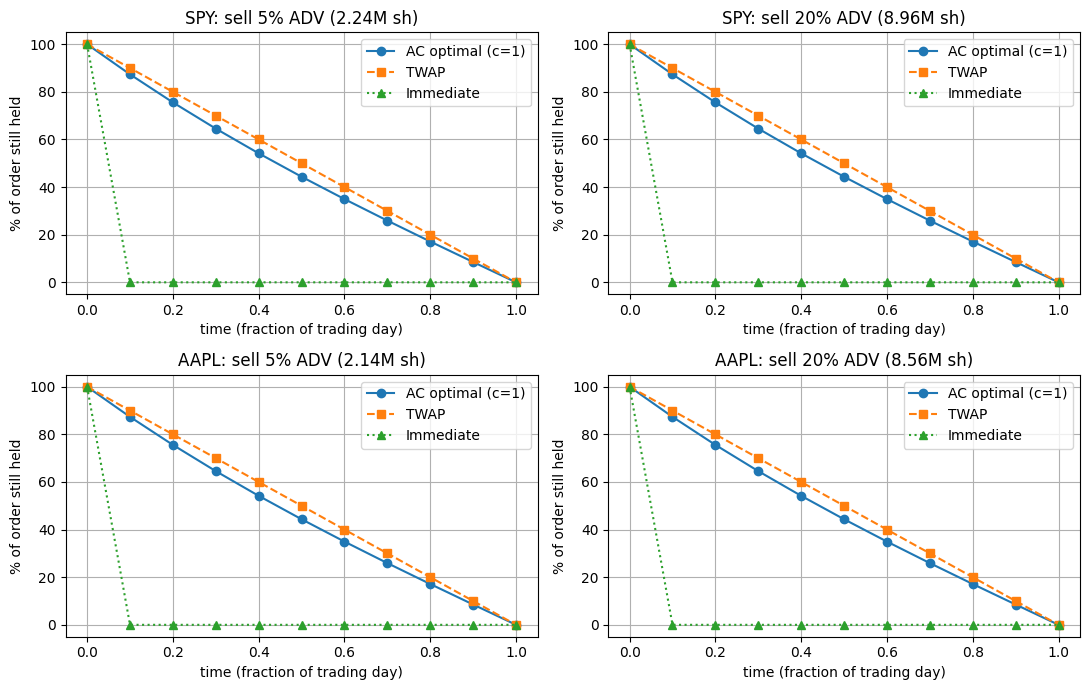

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
t = np.arange(N_STEPS + 1) * TAU
combos = [(tk, f) for tk in TICKERS for f in SIZES]
for ax, (tk, frac) in zip(axes.ravel(), combos):
    X = frac * params[tk]['adv']
    for name, style in [('AC optimal (c=1)', 'o-'), ('TWAP', 's--'), ('Immediate', '^:')]:
        ax.plot(t, schedules[(tk, frac, name)] / X * 100, style, label=name)
    ax.set_title(f"{tk}: sell {int(frac*100)}% ADV ({X/1e6:,.2f}M sh)")
    ax.set_xlabel('time (fraction of trading day)')
    ax.set_ylabel('% of order still held')
    ax.legend()
plt.tight_layout()
plt.show()

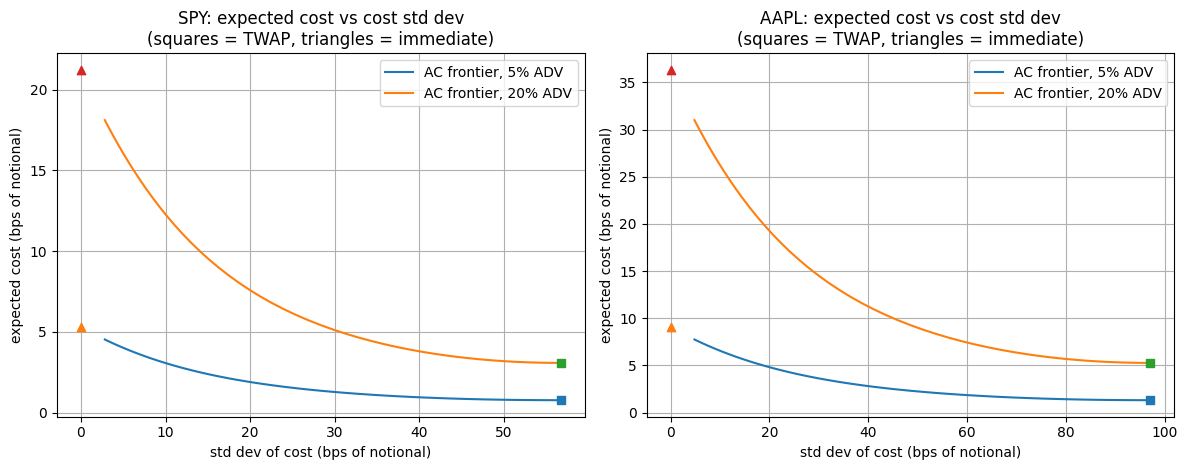

SPY 5% ADV frontier: cost 0.7697 to 4.5273 bps; std dev 2.8273 to 56.6313 bps
SPY 20% ADV frontier: cost 3.0787 to 18.1090 bps; std dev 2.8273 to 56.6313 bps
AAPL 5% ADV frontier: cost 1.3178 to 7.7512 bps; std dev 4.8407 to 96.9596 bps
AAPL 20% ADV frontier: cost 5.2711 to 31.0048 bps; std dev 4.8407 to 96.9596 bps


In [6]:
cgrid = np.logspace(-2, 3, 80)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
frontier_pts = {}
for ax, tk in zip(axes, TICKERS):
    p = params[tk]
    for frac in SIZES:
        X = frac * p['adv']
        pts = []
        for c in cgrid:
            lam = lam_from_c(c, p['gamma'], p['eta'], p['sig_usd'])
            h = ac_schedule(X, p['sig_usd'], p['gamma'], p['eta'], lam)
            cost, sd = schedule_stats(h, X, p['sig_usd'], p['gamma'], p['eta'])
            pts.append((1e4 * sd / (X * p['S0']), 1e4 * cost / (X * p['S0'])))
        pts = np.array(pts); frontier_pts[(tk, frac)] = pts
        ax.plot(pts[:, 0], pts[:, 1], '-', label=f"AC frontier, {int(frac*100)}% ADV")
        twp = schedule_stats(twap(X), X, p['sig_usd'], p['gamma'], p['eta'])
        imm = schedule_stats(immediate(X), X, p['sig_usd'], p['gamma'], p['eta'])
        ax.scatter([1e4 * twp[1] / (X * p['S0'])], [1e4 * twp[0] / (X * p['S0'])], marker='s', zorder=3)
        ax.scatter([1e4 * imm[1] / (X * p['S0'])], [1e4 * imm[0] / (X * p['S0'])], marker='^', zorder=3)
    ax.set_title(f"{tk}: expected cost vs cost std dev\n(squares = TWAP, triangles = immediate)")
    ax.set_xlabel('std dev of cost (bps of notional)')
    ax.set_ylabel('expected cost (bps of notional)')
    ax.legend()
plt.tight_layout()
plt.show()
for tk in TICKERS:
    for frac in SIZES:
        pts = frontier_pts[(tk, frac)]
        print(f"{tk} {int(frac*100)}% ADV frontier: cost {pts[:,1].min():.4f} to {pts[:,1].max():.4f} bps; "
              f"std dev {pts[:,0].min():.4f} to {pts[:,0].max():.4f} bps")

Sensitivity to risk aversion, 20% ADV order:
  c  kappaT ticker  lambda_per_usd  first_interval_pct  cost_bps  sd_bps
0.1  0.3162    SPY       2.735e-11               10.28     3.079   56.24
0.1  0.3162   AAPL       3.465e-11               10.28     5.272   96.29
0.3  0.5477    SPY       8.206e-11               10.84     3.082   55.41
0.3  0.5477   AAPL       1.039e-10               10.84     5.278   94.86
  1       1    SPY       2.735e-10               12.65     3.116   52.73
  1       1   AAPL       3.465e-10               12.65     5.334   90.28
  3   1.732    SPY       8.206e-10               17.01      3.32   46.74
  3   1.732   AAPL       1.039e-09               17.01     5.685   80.03
 10   3.162    SPY       2.735e-09               27.13     4.298   35.35
 10   3.162   AAPL       3.465e-09               27.13     7.358   60.53
 30   5.477    SPY       8.206e-09               41.79     6.392   24.03
 30   5.477   AAPL       1.039e-08               41.79     10.94   41.13
100   

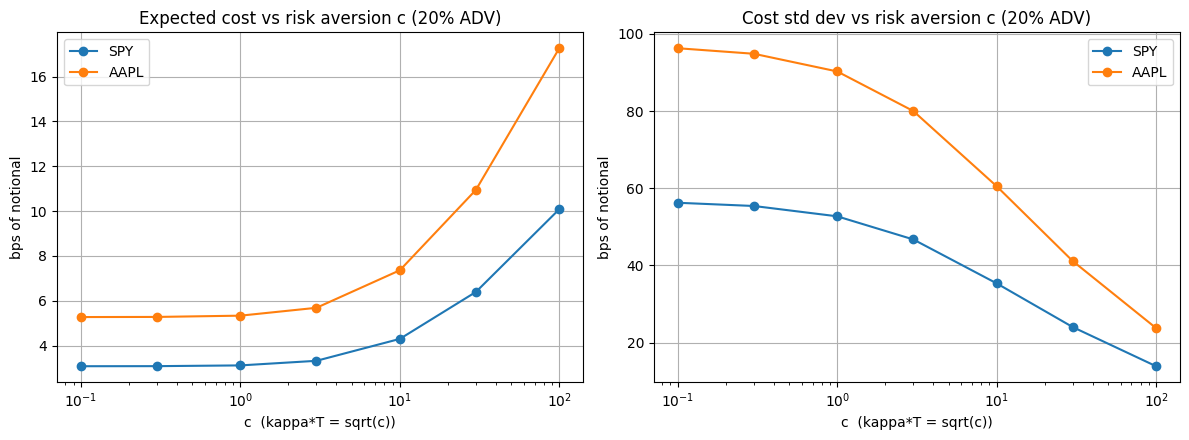

In [7]:
rows = []
for c in [0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0]:
    for tk in TICKERS:
        p = params[tk]; X = 0.20 * p['adv']
        lam = lam_from_c(c, p['gamma'], p['eta'], p['sig_usd'])
        h = ac_schedule(X, p['sig_usd'], p['gamma'], p['eta'], lam)
        cost, sd = schedule_stats(h, X, p['sig_usd'], p['gamma'], p['eta'])
        rows.append(dict(c=c, kappaT=np.sqrt(c), ticker=tk, lambda_per_usd=lam,
                         first_interval_pct=100 * (h[0] - h[1]) / X,
                         cost_bps=1e4 * cost / (X * p['S0']), sd_bps=1e4 * sd / (X * p['S0'])))
sens = pd.DataFrame(rows)
print("Sensitivity to risk aversion, 20% ADV order:")
print(sens.to_string(index=False, float_format=lambda v: f'{v:,.4g}'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for tk in TICKERS:
    s = sens[sens.ticker == tk]
    axes[0].semilogx(s.c, s.cost_bps, 'o-', label=tk)
    axes[1].semilogx(s.c, s.sd_bps, 'o-', label=tk)
axes[0].set_title('Expected cost vs risk aversion c (20% ADV)'); axes[0].set_xlabel('c  (kappa*T = sqrt(c))'); axes[0].set_ylabel('bps of notional'); axes[0].legend()
axes[1].set_title('Cost std dev vs risk aversion c (20% ADV)'); axes[1].set_xlabel('c  (kappa*T = sqrt(c))'); axes[1].set_ylabel('bps of notional'); axes[1].legend()
plt.tight_layout()
plt.show()

## Results
All numbers below are from the executed cells above (data: 501 sessions, 2024-11-19 to 2026-11-18; $c = 1$ unless stated).

- **Inputs.** SPY: $S_0 = \$730.20$, daily vol 1.06% (16.9% annualised), 60-day ADV 44.80M shares. AAPL: $S_0 = \$352.45$, daily vol 1.82% (28.9% annualised), 60-day ADV 42.80M shares. Both give $\gamma = \eta$ (because $\theta_P = \theta_T$): $1.73\times10^{-8}$ for SPY and $1.50\times10^{-8}$ for AAPL.
- **SPY, 5% ADV (2.24M sh, \$1.64bn):** optimal expected cost 0.779 bps (\$127k), cost std dev 52.7 bps; TWAP 0.770 bps (\$126k), std dev 56.7 bps; immediate 5.31 bps (\$868k), std dev 0.
- **SPY, 20% ADV (8.96M sh, \$6.54bn):** optimal 3.116 bps (\$2.04M), std dev 52.7 bps; TWAP 3.079 bps (\$2.01M), std dev 56.7 bps; immediate 21.23 bps (\$13.9M), std dev 0.
- **AAPL, 5% ADV (2.14M sh, \$754M):** optimal 1.334 bps, std dev 90.3 bps; TWAP 1.318 bps, std dev 97.0 bps; immediate 9.09 bps.
- **AAPL, 20% ADV (8.56M sh, \$3.02bn):** optimal 5.334 bps, std dev 90.3 bps; TWAP 5.271 bps, std dev 97.0 bps; immediate 36.35 bps.
- **Objective check (SPY, 20%):** optimal $E+\lambda V$ = 2,363,971 versus 2,390,395 for TWAP and 13,891,589 for immediate; the gradient at the optimum is $10^{-12}$ of its TWAP value, so the solution is stationary.
- **Frontier and sensitivity (SPY, 20%):** as $c$ goes from 0.1 to 100, expected cost rises from 3.08 to 10.08 bps and cost std dev falls from 56.2 to 13.9 bps. The first-interval sale rises from 10.3% to 61.8% of the order.
- **Caveats.** The impact coefficients $\theta_P = \theta_T = 0.10$ are assumptions, not estimated from data, so the dollar costs scale directly with them. The model is linear and single-asset, with no spread, no intraday volume curve and no price-dependent risk. Immediate sale has zero modelled risk by construction, which is why its std dev is 0. The bps std dev is identical for 5% and 20% orders because the linear model scales exactly with order size.

## Conclusions
1. **Selling fast is expensive; the schedule matters.** Selling 20% of SPY's average daily volume (8.96M shares, about $6.5bn) in one block would cost about 21.2 bps in market impact, against about 3.1 bps for a schedule spread over the day (Almgren-Chriss optimal 3.116 bps, TWAP 3.079 bps). For AAPL the same order costs 36.4 bps immediately and about 5.3 bps spread out.
2. **The optimal schedule is a trade between cost and risk.** The Almgren-Chriss solution sells faster at the start (holdings fall 100%, 87%, 76%, 65%, ... over the 10 intervals) to reduce exposure to price moves: its price risk is 52.7 bps against 56.7 bps for TWAP, at a slightly higher expected cost (3.116 vs 3.079 bps). Its objective (cost plus risk penalty) is lower than TWAP's (2.364M vs 2.390M USD) and the solution is stationary (gradient near 1e-12), as the theory requires.
3. **Risk aversion moves you along a frontier.** For the 20% ADV SPY order, raising risk aversion from 0.1 to 10 lowers risk from 56.2 to 35.4 bps and raises expected cost from 3.08 to 4.30 bps, with the first interval growing from 10% to 27% of the order. A trader with a tight risk budget should accept paying more in expected impact.
4. **Order size matters more than the schedule.** Cost rises with the order size: 0.78 bps at 5% ADV against 3.12 bps at 20% ADV for SPY under the same schedule, and AAPL is costlier than SPY (more volatile, same relative size).
5. **Limits.** The impact coefficients are assumed (10% of daily dollar volatility per unit of daily volume, for temporary and permanent impact), not estimated from trade data, so the dollar figures depend on that assumption; the model has linear impact, no spreads or fees, and no intraday volume pattern.

**Takeaway for the interview:** optimal execution is a mean-variance problem on trading costs: the schedule is chosen by how much price risk you are willing to carry while you wait, and the main driver of cost is how large the order is relative to volume.